# 01 — Offline Scoring Load Analysis

**Project:** Integration of AI Tools into the Inclusive Ecosystem of a Modern University:
Barriers and Opportunities for Students with Visual and Hearing Impairments  
**Authors:** Bissenbai Zhalgas, Zhussip Nurdaulet  
**Repository:** [inclusive-ai-university](https://github.com/ZhalgasB/inclusive-ai-university)

This notebook reproduces the analysis of the **offline scoring program** using saved
timings for input batches of **8, 40 and 80 records**. It does not call an AI model,
collect new timings, or test the research hypothesis about AI versus manual output quality.

**Technical question:** How does the observed execution time of one `evaluate()` call
change with the number of input records?

The larger batches repeat the same eight synthetic annotations with unique identifiers.
They are workload fixtures, not independent students, educational materials, or new AI outputs.
Each measured call processes the entire batch, so milliseconds are reported **per call**.

The recorded collection command used CPU-only Docker with `--cpus="1.0"`,
`--memory="1g"` and `--memory-swap="1g"`. Resource limits do not eliminate host noise.
Each size has its own warm-up. A fixed seed shuffles the order of the three sizes.

**Execution:** restart the kernel and run all cells in order. Save the notebook with outputs.
The same workflow can be executed with `jupyter nbconvert --to notebook --execute --inplace`.

## 1. Setup and fixed analysis parameters

The notebook locates the repository from either its root or the `notebooks/` directory.
Data processing and plotting are imported from `src/`, so the notebook and command-line
tools use the same implementation. Bootstrap resampling uses **seed 42** and **2,000 resamples**.
These are resamples of existing timings, not additional benchmark executions.

In [1]:
from pathlib import Path
import hashlib
import platform
import sys

import numpy as np
import pandas as pd
import yaml
from IPython.display import display, Markdown, Image

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((path for path in candidates
             if (path / "src/process_data.py").is_file()
             and (path / "configs/load.yaml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook inside the inclusive-ai-university repository.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from process_data import load_logs, prepare_measurements, analyze_log
from visualize import make_figures, export_figures, plt

SEED = 42
BOOTSTRAP_RESAMPLES = 2000
np.random.seed(SEED)
settings = yaml.safe_load((ROOT / "configs/load.yaml").read_text(encoding="utf-8"))
RAW_PATH = ROOT / settings["log_path"]
PROCESSED_DIR = ROOT / "data/processed"
FIGURES_DIR = ROOT / "reports/figures"
EXPECTED_SIZES = sorted(settings["input_sizes"])

print(f"Source: {RAW_PATH.relative_to(ROOT)}")
print(f"Input sizes: {EXPECTED_SIZES}; bootstrap resamples={BOOTSTRAP_RESAMPLES}; seed={SEED}")
print(f"Analysis environment: Python {platform.python_version()}, NumPy {np.__version__}, Pandas {pd.__version__}")

Source: data\raw\load_run.jsonl
Input sizes: [8, 40, 80]; bootstrap resamples=2000; seed=42
Analysis environment: Python 3.12.0, NumPy 2.5.3, Pandas 3.0.6


## 2. Data ingestion and schema validation

`load_logs()` validates JSONL fields, timestamps, durations, statuses and unique attempt IDs.
Invalid input stops analysis instead of silently disappearing from the dataset.
The table below shows the original counts, including warm-up and execution errors.
The SHA-256 digest identifies the exact raw file used for this analysis.

In [2]:
raw_sha256 = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
raw = load_logs(RAW_PATH)
raw_counts = (raw.groupby(["input_records", "phase", "status"], sort=True)
             .size().rename("records").reset_index())
print(f"Raw records: {len(raw)}")
print(f"Raw SHA-256: {raw_sha256}")
display(raw_counts)

Raw records: 330
Raw SHA-256: 95197b9d044d5b050469ad5848dd3c636acec13f392b8e51b41093b4c75f9e7c


,input_records,phase,status,records
0,8,benchmark,success,100
1,8,warmup,success,10
2,40,benchmark,success,100
3,40,warmup,success,10
4,80,benchmark,success,100
5,80,warmup,success,10


## 3. Warm-up filtering, failures and nondestructive outlier flags

Only warm-up is excluded from the working dataset. All measured execution failures and
all IQR-flagged durations remain present. Failure rate uses **all measured attempts** as
its denominator; a failed call is not treated as a missing row or a zero-duration success.

IQR equals p75 minus p25. Successful durations outside
`[p25 - 1.5 × IQR, p75 + 1.5 × IQR]` are flagged within each run and workload.
A flag indicates an unusual duration; it does not establish hardware noise as the cause.
These execution failures are distinct from failed AI/manual outputs in the annotation fixture.

In [3]:
measurements, guardrails = prepare_measurements(raw)
warmup_mask = raw["phase"].eq("warmup")
print(f"Warm-up excluded: {int(warmup_mask.sum())}")
print(f"Warm-up execution errors: {int((warmup_mask & raw['status'].eq('error')).sum())}")
print(f"Working measurements retained: {len(measurements)}")
guardrail_columns = ["input_records", "attempts", "successful_runs", "failed_runs",
                     "execution_failure_rate_pct", "iqr_checked_runs", "latency_outliers"]
display(guardrails.sort_values("input_records")[guardrail_columns].reset_index(drop=True))

Warm-up excluded: 30
Warm-up execution errors: 0
Working measurements retained: 300


,input_records,attempts,successful_runs,failed_runs,execution_failure_rate_pct,iqr_checked_runs,latency_outliers
0,8,100,100,0,0.0,100,13
1,40,100,100,0,0.0,100,8
2,80,100,100,0,0.0,100,8


## 4. Statistical aggregation and CSV export

`analyze_log()` runs the same processing and export workflow as the command-line script.
Mean, sample SD (`ddof=1`), p50, p95 and p99 describe **successful** calls, including outliers.
Failure counts remain visible in the accompanying guardrails. Quantiles use linear interpolation.

The 95% percentile-bootstrap intervals describe uncertainty in a statistic, while p25–p75
describes the spread of individual durations. Bootstrap latency intervals are conditional on
success and assume independent, identically distributed calls within a run. Serial correlation
or drift can make them too narrow. With 100 calls per size, p99 is particularly exploratory.

`compute_goodput_calls_per_s` is successful calls divided by the summed measured function time
of **all** attempts, including failures. It is not server RPS or AI generation throughput.
Undefined statistics are stored as empty CSV cells, not invented zeros.

The two files in `data/processed/` are regenerated from the raw log; the raw log stays unchanged.

In [4]:
_, measurements, summary = analyze_log(
    RAW_PATH, PROCESSED_DIR,
    bootstrap_resamples=BOOTSTRAP_RESAMPLES, seed=SEED,
)
summary = summary.sort_values("input_records").reset_index(drop=True)
metric_names = {
    "input_records": "Records / call",
    "attempts": "Attempts",
    "mean_success_ms": "Mean (ms)",
    "sd_success_ms": "SD (ms)",
    "p50_success_ms": "p50 (ms)",
    "p95_success_ms": "p95 (ms)",
    "p99_success_ms": "p99 (ms)",
    "compute_goodput_calls_per_s": "Compute goodput (calls/s)",
}
display(summary[list(metric_names)].rename(columns=metric_names).round(6))
ci_columns = ["input_records"]
for percentile in (50, 95, 99):
    ci_columns.extend([f"p{percentile}_success_ms_ci95_low", f"p{percentile}_success_ms_ci95_high"])
display(summary[ci_columns].round(6))
for name in ("measurements.csv", "metrics_summary.csv"):
    print(f"Saved: {(PROCESSED_DIR / name).relative_to(ROOT)}")

,Records / call,Attempts,Mean (ms),SD (ms),p50 (ms),p95 (ms),p99 (ms),Compute goodput (calls/s)
0,8,100,0.080749,0.002326,0.079917,0.084890,0.090283,12384.089566
1,40,100,0.337364,0.013318,0.335417,0.353972,0.370444,2964.159781
2,80,100,0.648870,0.007790,0.646979,0.666375,0.676840,1541.139660


,input_records,p50_success_ms_ci95_low,p50_success_ms_ci95_high,p95_success_ms_ci95_low,p95_success_ms_ci95_high,p99_success_ms_ci95_low,p99_success_ms_ci95_high
0,8,0.079833,0.080021,0.082890,0.088112,0.084906,0.093500
1,40,0.333291,0.337065,0.349491,0.366987,0.354076,0.422625
2,80,0.646146,0.648812,0.655125,0.671925,0.666212,0.677500


Saved: data\processed\measurements.csv
Saved: data\processed\metrics_summary.csv


## 5. Visualization and publication export

The plotting module verifies that the summary and working measurements describe the same runs.
It reads the stored confidence bounds rather than bootstrapping three already-aggregated points.

- **Figure 1:** p50/p95/p99 versus input size; capped bars show 95% CI and the grey band shows p25–p75.
- **Figure 2:** distributions for the three input sizes; boxes show p25–p75, outliers are retained,
  and a separate marker/bar shows the median with its 95% CI.

Axes state records per call and milliseconds per call. The latency scale starts at zero.
A colorblind-safe palette, distinct markers, line styles and hatches support accessible reading.
Each figure is exported as a **vector PDF** and a **300-DPI PNG**.

Saved: reports\figures\fig1_latency_vs_load.pdf
Saved: reports\figures\fig1_latency_vs_load.png
Saved: reports\figures\fig2_distribution_boxplot.pdf
Saved: reports\figures\fig2_distribution_boxplot.png


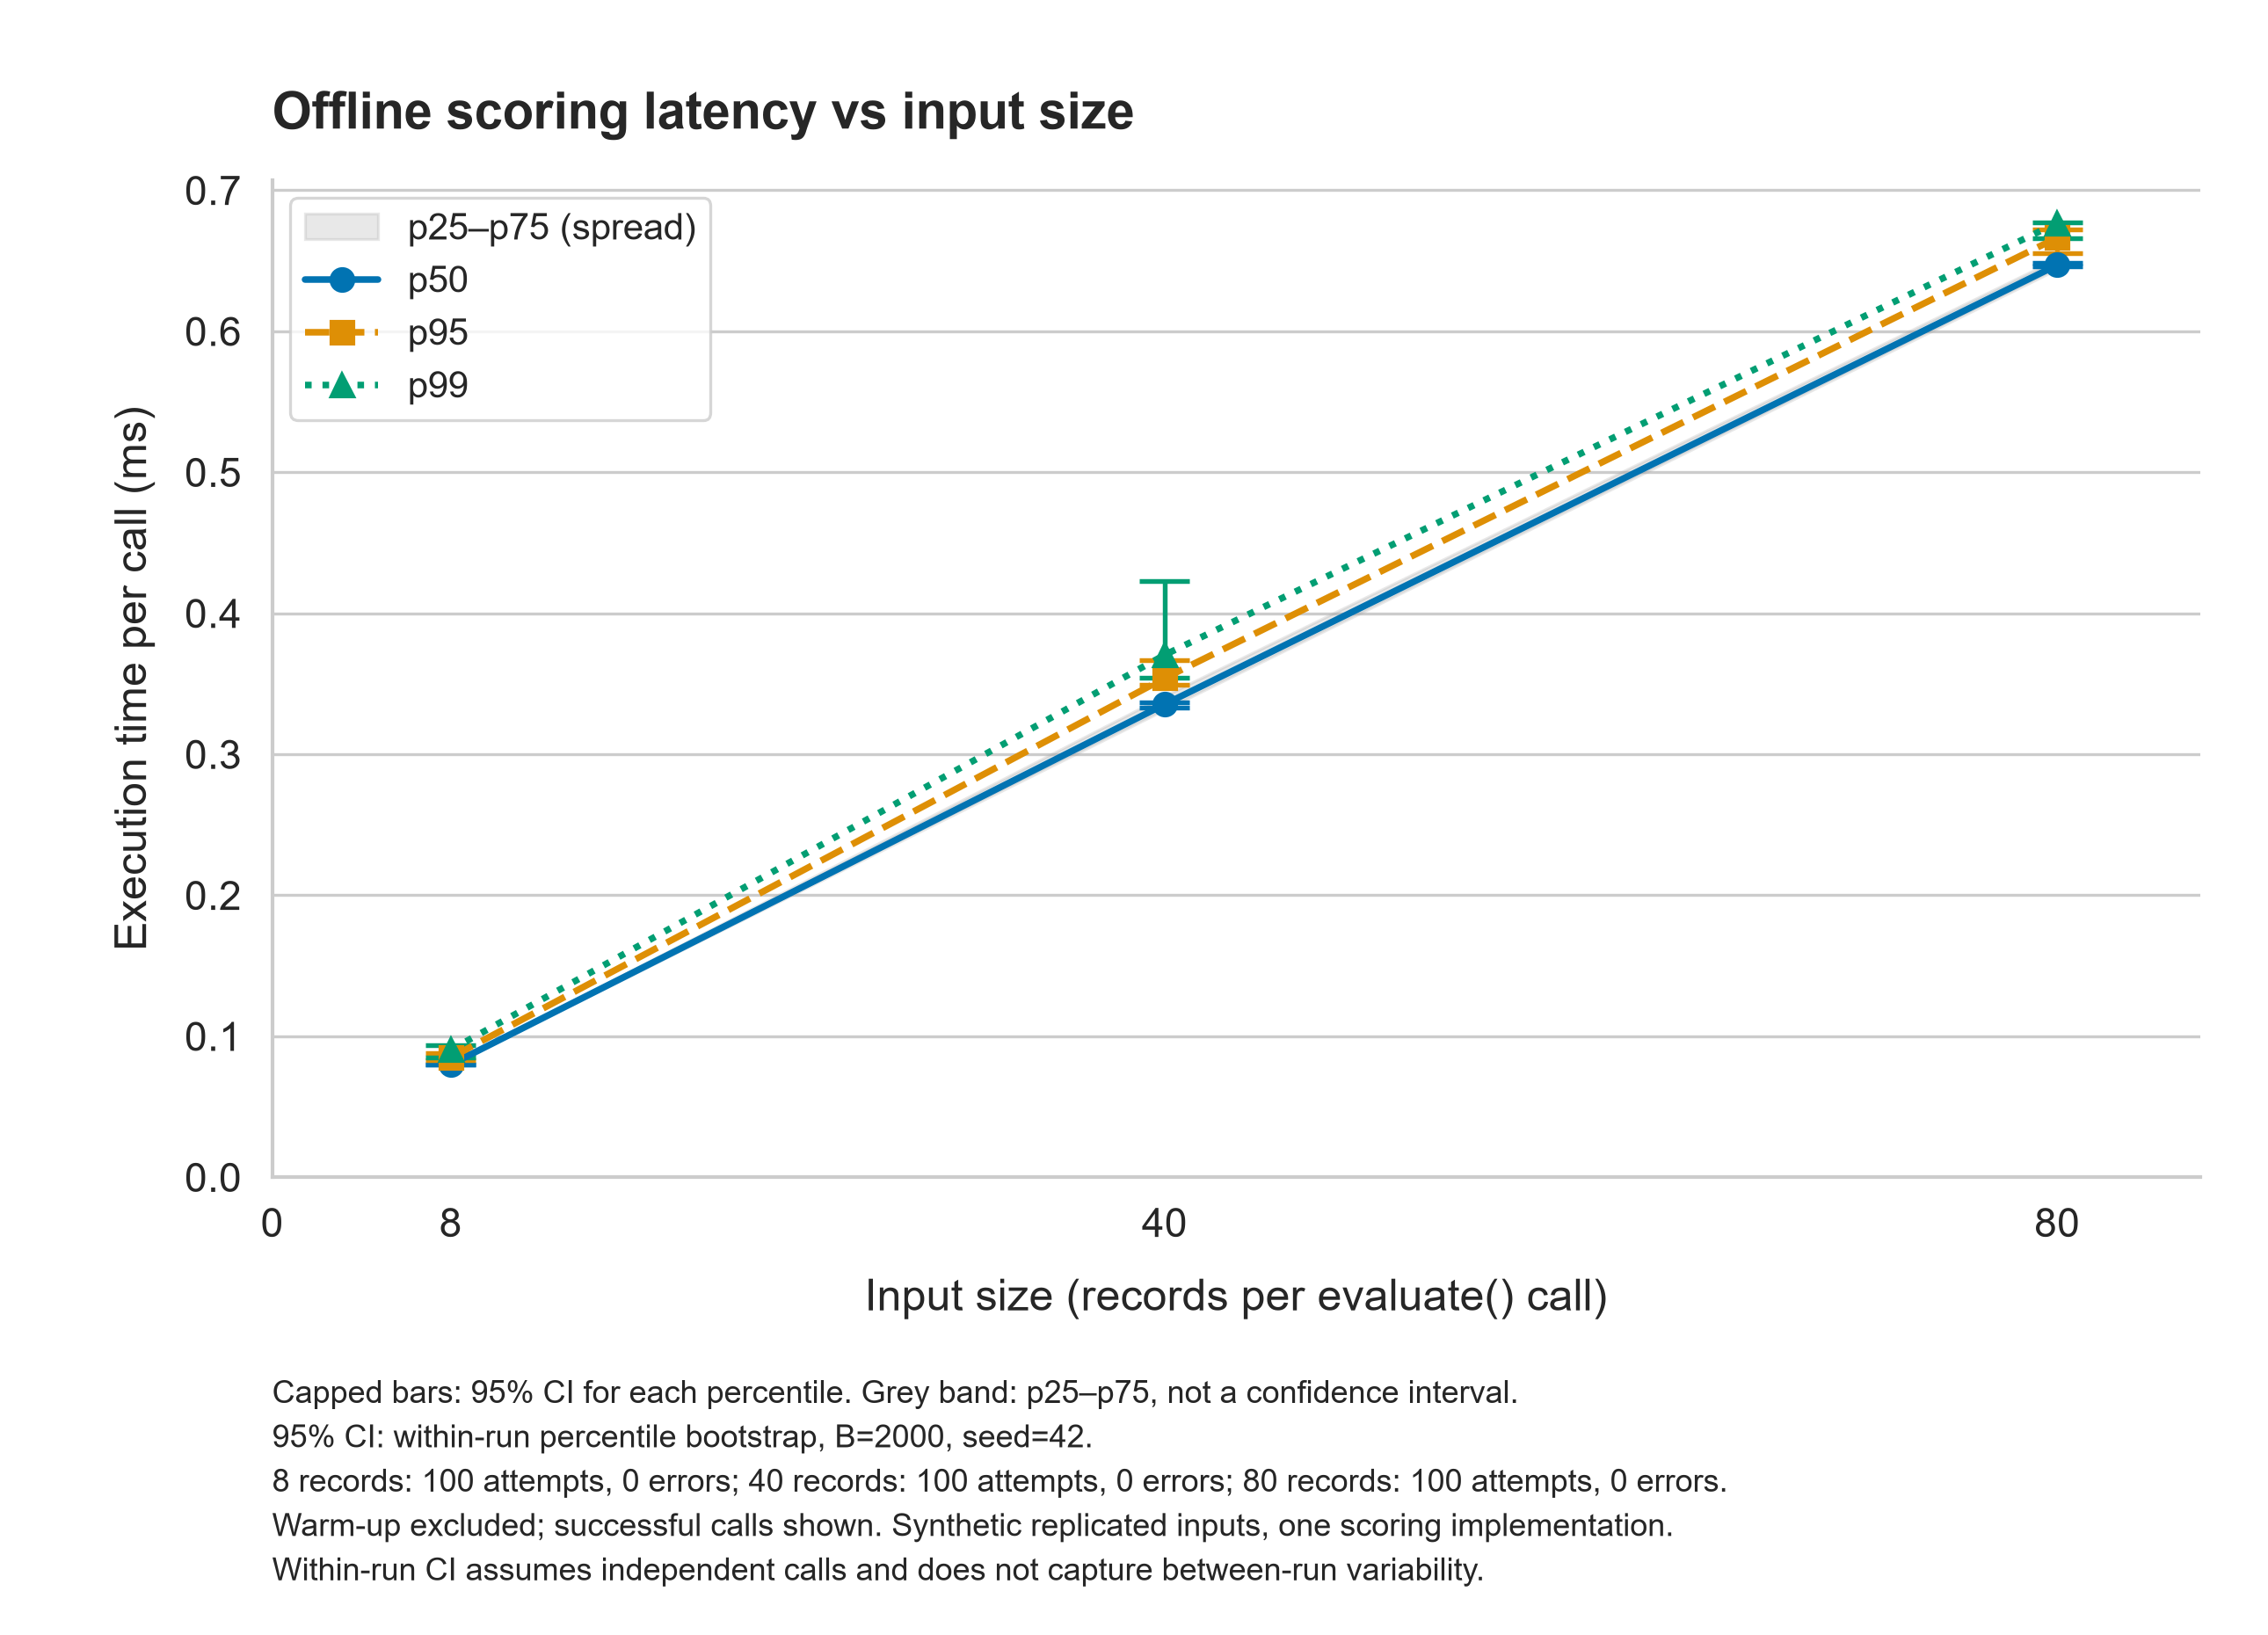

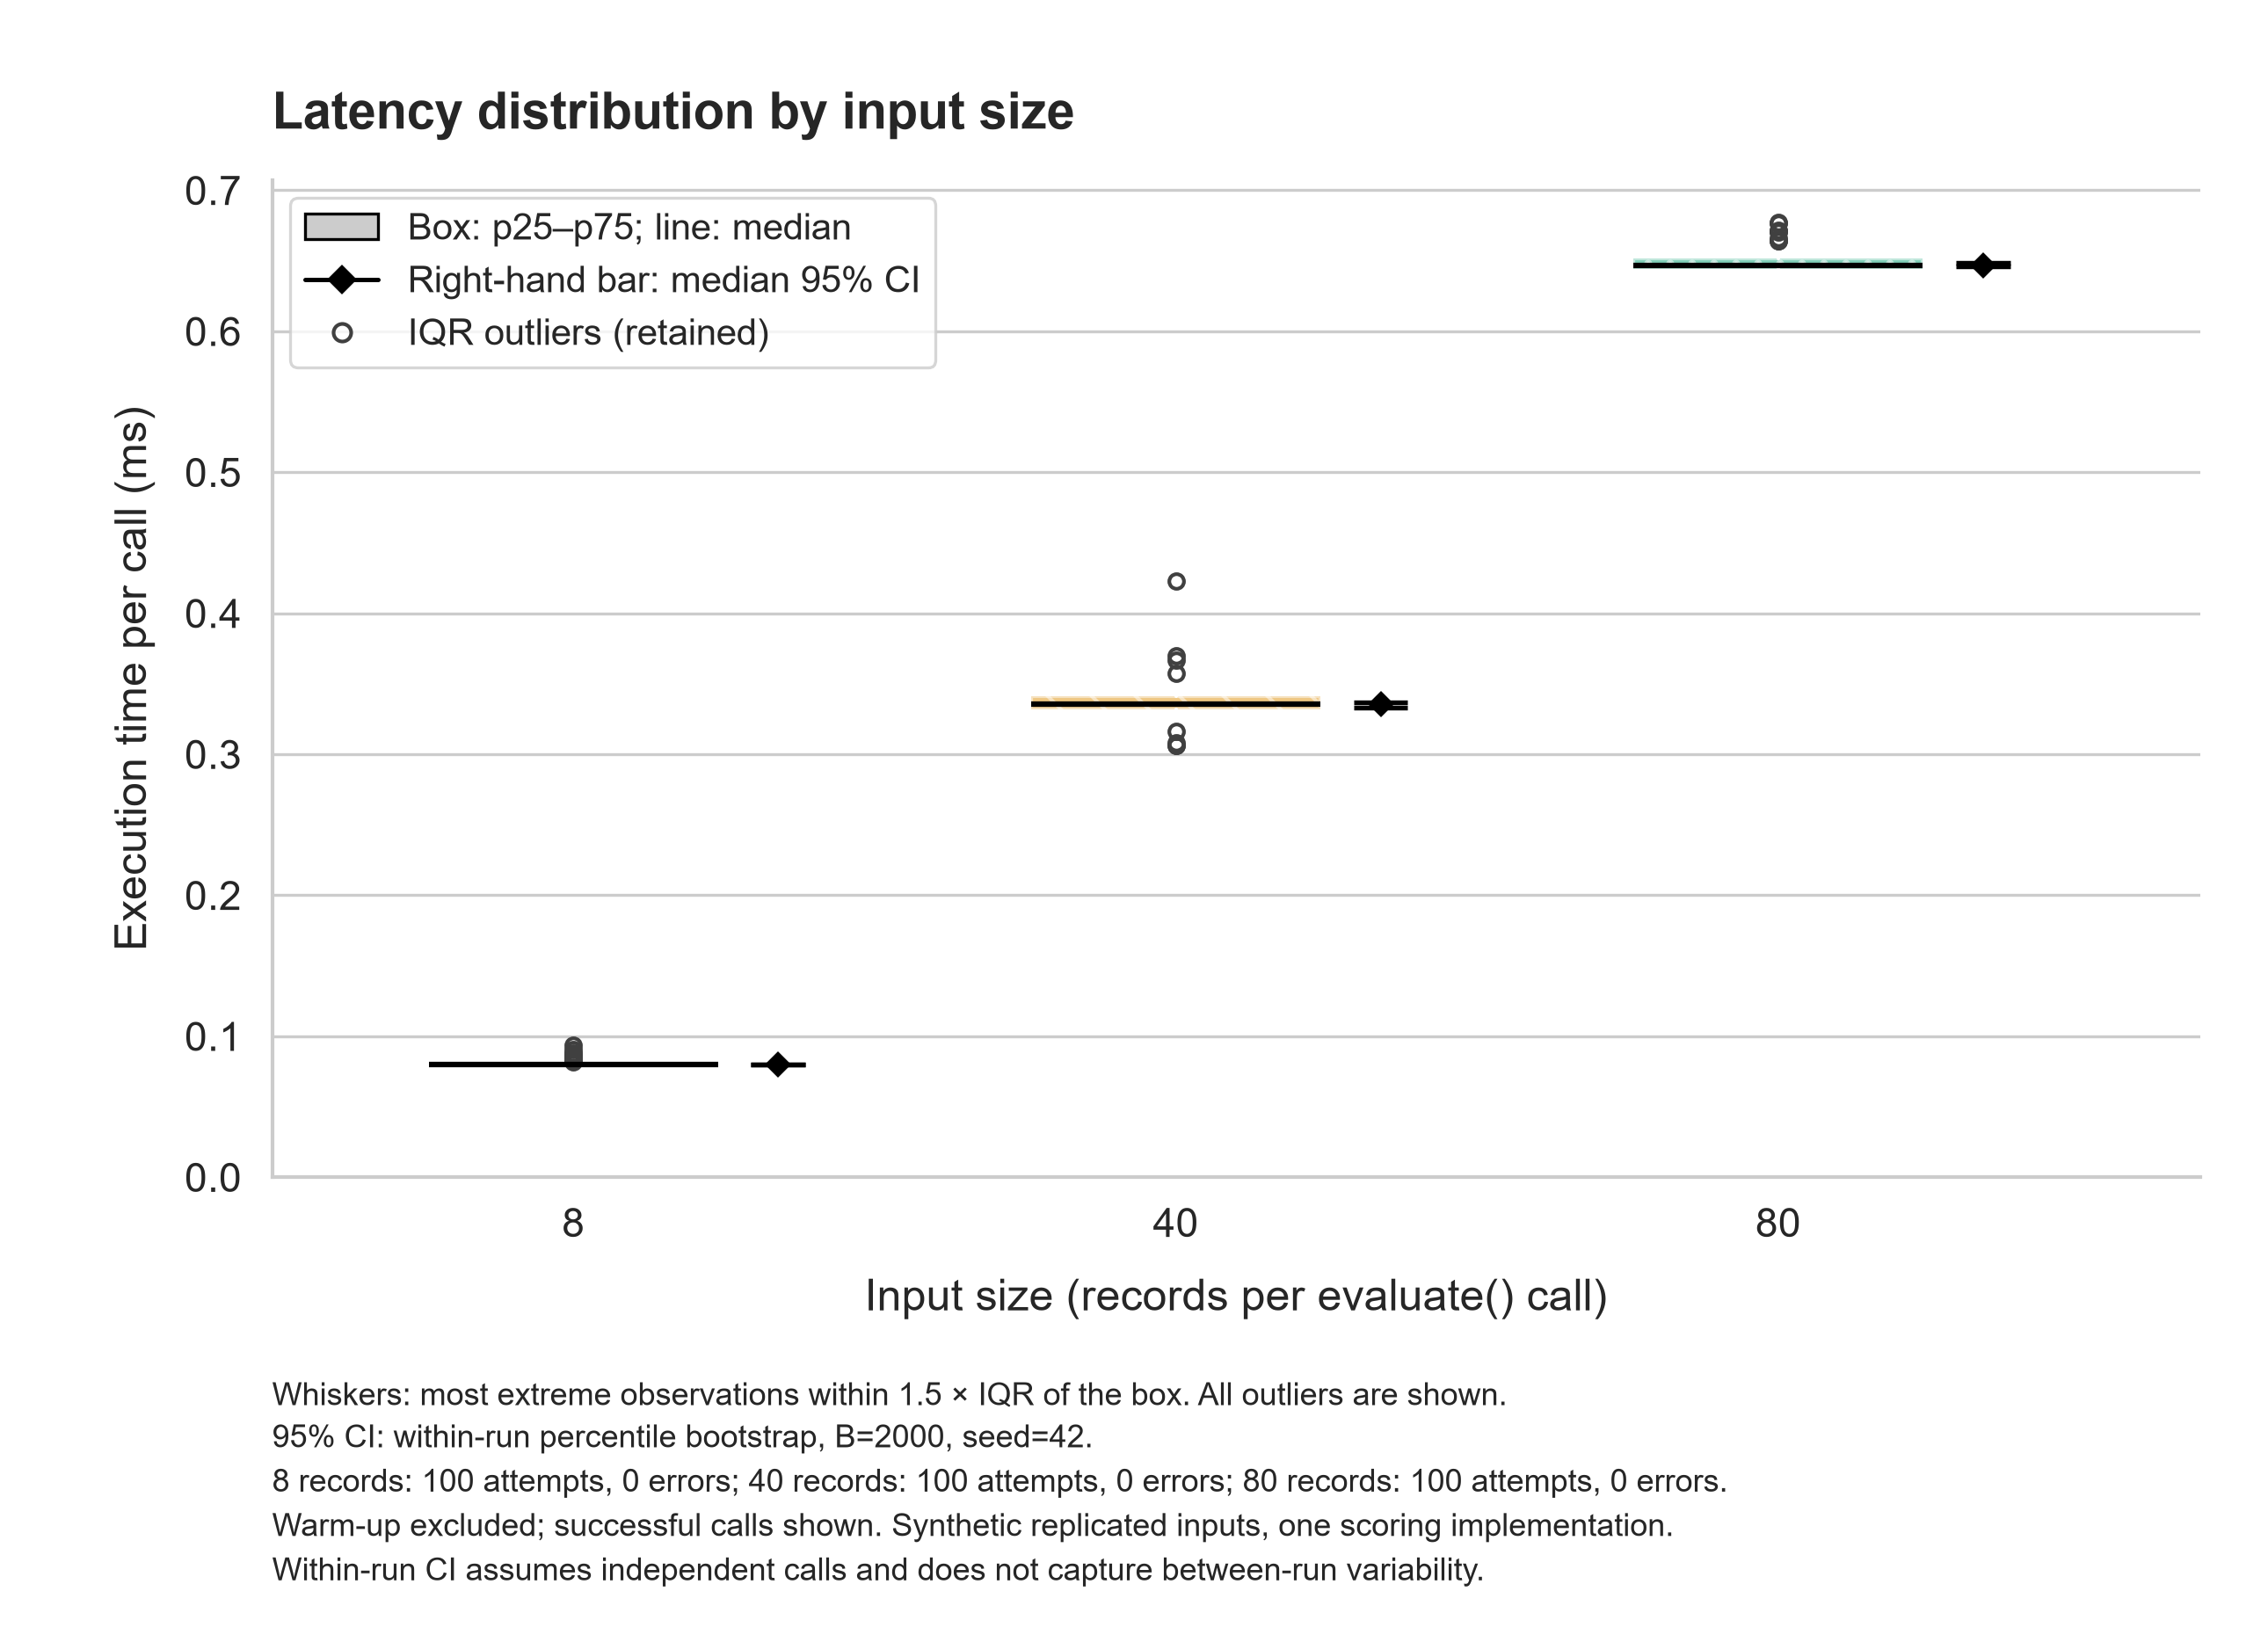

In [5]:
figures = make_figures(summary, measurements)
try:
    exported_paths = export_figures(figures, FIGURES_DIR)
finally:
    for figure in figures.values():
        plt.close(figure)
for path in exported_paths:
    print(f"Saved: {path.relative_to(ROOT)}")
for name in ("fig1_latency_vs_load", "fig2_distribution_boxplot"):
    display(Image(filename=str(FIGURES_DIR / f"{name}.png"), width=900))

## 6. Results and interpretation

The following description is calculated from the current summary rather than hard-coded.
It is a descriptive comparison of input volumes for one scoring implementation.

In [6]:
smallest, largest = summary.iloc[0], summary.iloc[-1]
size_ratio = largest["input_records"] / smallest["input_records"]
first_median = smallest["p50_success_ms"]
last_median = largest["p50_success_ms"]
ratio_text = (f"{last_median / first_median:.2f}×" if first_median > 0 else "undefined (zero reference median)")
total_attempts = int(summary["attempts"].sum())
total_errors = int(summary["failed_runs"].sum())
display(Markdown(
    f"The observed median batch time was **{first_median:.6f} ms** for "
    f"**{int(smallest['input_records'])} records** and **{last_median:.6f} ms** for "
    f"**{int(largest['input_records'])} records**. The endpoint input-size ratio was "
    f"**{size_ratio:.1f}×** and the observed median-time ratio was **{ratio_text}**. "
    f"The log contains **{total_errors} execution errors out of {total_attempts} measured attempts**."
))
print("Interpretation is restricted to this synthetic workload and these recorded runs.")

The observed median batch time was **0.079917 ms** for **8 records** and **0.646979 ms** for **80 records**. The endpoint input-size ratio was **10.0×** and the observed median-time ratio was **8.10×**. The log contains **0 execution errors out of 300 measured attempts**.

Interpretation is restricted to this synthetic workload and these recorded runs.


### Limits and relation to the research project

- One run per input size does not estimate variability between independent runs or machines.
- Repeated calls and copied annotations are not independent research materials.
- The three input sizes are workload conditions, not a Baseline/Proposed algorithm comparison.
- These timings do not establish AI output quality, accessibility, student outcomes, or the project's H0/H1.
- The scientific manual-versus-AI comparison still needs actual collected outputs and separate reference annotations.
  The original synthetic quality scores only test the scoring software.

This notebook supplies the reproducible analysis component of Task 3. The domain model,
final README and research comparison remain separate deliverables.

## 7. Reproducibility checks

These checks verify retained attempts, agreement with the configured load matrix, saved artifacts,
and preservation of the raw input. A nonzero execution failure rate is reported above rather than
hidden by filtering or used as a reason to delete observations.

In [7]:
expected_artifacts = [PROCESSED_DIR / "measurements.csv", PROCESSED_DIR / "metrics_summary.csv", *exported_paths]
checks = {
    "Raw log unchanged": hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == raw_sha256,
    "All working attempts retained": len(measurements) == int((~raw["phase"].eq("warmup")).sum()),
    "Warm-up absent from analysis": bool(measurements["phase"].eq("benchmark").all()),
    "Configured input sizes present": summary["input_records"].astype(int).tolist() == EXPECTED_SIZES,
    "One series per configured size": len(summary) == len(EXPECTED_SIZES),
    "Configured measured counts match": bool(summary["attempts"].eq(settings["measurement_runs"]).all()),
    "Configured warm-up count matches": int(warmup_mask.sum()) == settings["warmup_runs"] * len(EXPECTED_SIZES),
    "Failure counts retained": int(summary["failed_runs"].sum()) == int(measurements["status"].eq("error").sum()),
    "Tables and four figure exports exist": len(exported_paths) == 4 and all(path.is_file() and path.stat().st_size > 0 for path in expected_artifacts),
}
display(pd.DataFrame({"Check": list(checks), "Passed": list(checks.values())}))
failed_checks = [name for name, passed in checks.items() if not passed]
if failed_checks:
    raise AssertionError("Reproducibility checks failed: " + "; ".join(failed_checks))
print("All checks passed. Save the executed notebook with its tables and figure outputs.")

,Check,Passed
0,Raw log unchanged,True
1,All working attempts retained,True
2,Warm-up absent from analysis,True
3,Configured input sizes present,True
4,One series per configured size,True
5,Configured measured counts match,True
6,Configured warm-up count matches,True
7,Failure counts retained,True
8,Tables and four figure exports exist,True


All checks passed. Save the executed notebook with its tables and figure outputs.
